# **Ethereum and Bitcoin Return Machine Learning Comparison**

This analysis will focus on cryptocurrency and trying to predict whether Bitcoin or Ethereum will have the higher return the next day using different machine learning algorithms.

First we will use yfinance to download the data and transform it into log returns to make it question ready. We will also create the binary of whether or not BTC return is greater than ETH. The features are the last 7 days of returns for both BTC and ETH (14 features), and the target is whether BTC beats ETH on the next day. ETH data on Yahoo Finance only starts in November 2017, so that is where the data starts. Like the sector analysis, the dates and seeds are set in `src/config.py` and the prices are saved in `data/` so the results stay the same.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # make the src/ package importable

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import binomtest
from sklearn.model_selection import TimeSeriesSplit

from src.config import FIGURES_DIR, SEED
from src.crypto_models import (C_VALUES, Net, error_rate, fit_predict_all, make_lag_features,
                               make_logreg, make_rf, make_xgb, train_net)
from src.data import load_prices

np.random.seed(SEED)
FIGURES_DIR.mkdir(exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)
torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
crypto = load_prices("crypto_prices", ["BTC-USD", "ETH-USD"]).rename(columns={"BTC-USD": "BTC", "ETH-USD": "ETH"})
print(f"Missing values: {crypto.isna().sum().to_dict()}")
crypto = crypto.dropna()
crypto_ret = np.log(crypto / crypto.shift(1)).dropna()
print(f"Daily returns: {len(crypto_ret)} days ({crypto_ret.index[0].date()} to {crypto_ret.index[-1].date()})")


X2, y2 = make_lag_features(crypto_ret)
print(f"Feature matrix: {X2.shape}, target: {y2.shape}")

Loaded cached crypto_prices.parquet: 3652 days x 2 tickers
Missing values: {'BTC': 0, 'ETH': 557}
Daily returns: 3094 days (2017-11-10 to 2026-04-30)
Feature matrix: (3087, 14), target: (3087,)


We split the data into 60% train, 20% validation and 20% test in time order, so the models are always trained on the past and tested on the future. We will next check if the dataset is balanced or skewed for our assumption that it is balanced before training a logistic regression model.

In [3]:
n = len(X2)
train_end, val_end = int(n * 0.60), int(n * 0.80)
X_train, y_train = X2.iloc[:train_end], y2.iloc[:train_end]
X_val,   y_val   = X2.iloc[train_end:val_end], y2.iloc[train_end:val_end]
X_test,  y_test  = X2.iloc[val_end:], y2.iloc[val_end:]

for name, Xs, ys in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name:>5}: n={len(ys):4d}  {Xs.index[0].date()} to {Xs.index[-1].date()}  "
          f"P(BTC outperforms)={ys.mean():.3f}")

Train: n=1852  2017-11-17 to 2022-12-12  P(BTC outperforms)=0.525
  Val: n= 617  2022-12-13 to 2024-08-20  P(BTC outperforms)=0.556
 Test: n= 618  2024-08-21 to 2026-04-30  P(BTC outperforms)=0.553


The dataset is not imbalanced, the proportion of y=1 (cases where BTC outperforms ETH) is 52.5% in the train set, 55.6% in the validation set, and 55.3% in the test set. This seems stable over the splits which means no major distribution shift over time.

The baseline we will compare the models against always predicts whatever happened more often in the training set, which here is BTC outperforming ETH. Any model has to beat this to show that it actually learned something.

In [4]:
majority_class = int(y_train.mean() >= 0.5)
predictions = {"Naive Baseline": {split: np.full(len(Xs), majority_class)
                                  for split, Xs in [("train", X_train), ("val", X_val), ("test", X_test)]}}
print(f"Training majority class: {majority_class} "
      f"({'BTC' if majority_class else 'ETH'} outperforms)")

Training majority class: 1 (BTC outperforms)


Daily returns are really small numbers (around 0.01 to 0.05), so for the logistic regression and the neural network the features are standardized using only the training data. Without this the regularization barely does anything. The tree models don't need this since they don't depend on the scale of the features. The models themselves are defined in `src/crypto_models.py`.

In [5]:
def predict_splits(predict_fn):
    return {"train": predict_fn(X_train), "val": predict_fn(X_val), "test": predict_fn(X_test)}

Now that our assumptions are good we will do the logistic regression and regularize the features using elastic net (a mix of lasso and ridge). We will iterate between the different hyperparameters until we get one that gives us the lowest validation error.

Best C: 1 | validation error: 0.4392


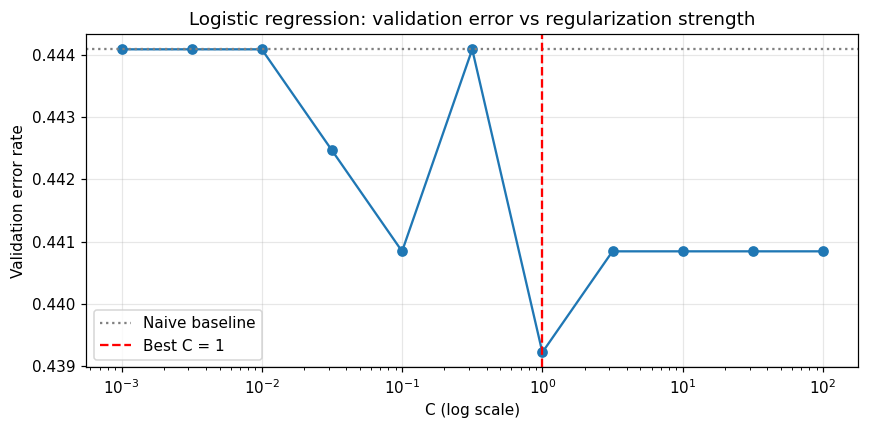

Non-zero coefficients: 14 / 14


In [6]:
val_errors = [error_rate(y_val, make_logreg(C).fit(X_train, y_train).predict(X_val)) for C in C_VALUES]
best_C = float(C_VALUES[int(np.argmin(val_errors))])
print(f"Best C: {best_C:.4g} | validation error: {min(val_errors):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(C_VALUES, val_errors, marker="o")
ax.axhline(error_rate(y_val, predictions["Naive Baseline"]["val"]), color="gray", linestyle=":",
           label="Naive baseline")
ax.axvline(best_C, color="red", linestyle="--", label=f"Best C = {best_C:.3g}")
ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("Validation error rate")
ax.set_title("Logistic regression: validation error vs regularization strength")
ax.legend(); plt.tight_layout()
fig.savefig(FIGURES_DIR / "logreg_validation.png", dpi=150, bbox_inches="tight")
plt.show()

logreg = make_logreg(best_C).fit(X_train, y_train)
predictions["Logistic Regression"] = predict_splits(logreg.predict)
coefs = pd.Series(logreg[-1].coef_.ravel(), index=X2.columns)
print(f"Non-zero coefficients: {(coefs != 0).sum()} / {len(coefs)}")

The best C from our scale was C = 1. The errors seem to be relatively similar where the Train error is 0.4681, Val error is 0.4392, and Test error is 0.4628. The validation error only changes between 0.439 and 0.444 across the whole grid though, so the best C is not really much better than the others.

Now we will train boosting and bagging methods (random forest and XGBoost) in order to compare our logistic regression model with.

In [7]:
rf_model = make_rf().fit(X_train, y_train)
predictions["Random Forest"] = predict_splits(rf_model.predict)

xgb_model = make_xgb().fit(X_train, y_train)
predictions["XGBoost"] = predict_splits(xgb_model.predict)

for name in ["Random Forest", "XGBoost"]:
    p = predictions[name]
    print(f"{name:>14}: train {error_rate(y_train, p['train']):.4f} | "
          f"val {error_rate(y_val, p['val']):.4f} | test {error_rate(y_test, p['test']):.4f}")

 Random Forest: train 0.4152 | val 0.4587 | test 0.4644
       XGBoost: train 0.3251 | val 0.4652 | test 0.4887


Both models seem to overfit, the training and test error are spread apart. XGBoost seems to overfit more however, having a difference of 0.1636 between its training and test errors.

We will train a small neural network in Pytorch to compare against the other machine learning models.

In [8]:
nn_predict, nn_best_epoch = train_net(X_train, y_train, X_val, y_val)
predictions["Neural Network"] = predict_splits(nn_predict)
n_params = sum(p.numel() for p in Net(X2.shape[1]).parameters())
p = predictions["Neural Network"]
print(f"Parameters: {n_params} | best epoch: {nn_best_epoch}")
print(f"Neural Net: train {error_rate(y_train, p['train']):.4f} | "
      f"val {error_rate(y_val, p['val']):.4f} | test {error_rate(y_test, p['test']):.4f}")

Parameters: 177 | best epoch: 296
Neural Net: train 0.4217 | val 0.4765 | test 0.4628


Now we compare the models. Since the test set only has about 600 days, we also add a 95% confidence interval for the accuracy and a binomial test to check if a model is actually better than the baseline or just got lucky.

In [9]:
baseline_test_acc = 1 - error_rate(y_test, predictions["Naive Baseline"]["test"])
rows = {}
for name, p in predictions.items():
    correct = int((p["test"] == y_test.values).sum())
    test = binomtest(correct, len(y_test), p=baseline_test_acc, alternative="greater")
    ci = binomtest(correct, len(y_test)).proportion_ci(confidence_level=0.95)   # two-sided CI
    rows[name] = {
        "Train Error": error_rate(y_train, p["train"]),
        "Val Error": error_rate(y_val, p["val"]),
        "Test Error": error_rate(y_test, p["test"]),
        "Test Acc 95% CI": f"[{ci.low:.3f}, {ci.high:.3f}]",
        "p (beats baseline)": np.nan if name == "Naive Baseline" else test.pvalue,
    }
results = pd.DataFrame(rows).T
print(results.to_string(float_format=lambda v: f"{v:.4f}"))

                    Train Error Val Error Test Error Test Acc 95% CI p (beats baseline)
Naive Baseline           0.4746    0.4441     0.4466  [0.513, 0.593]                NaN
Logistic Regression      0.4681    0.4392     0.4628  [0.497, 0.577]             0.8023
Random Forest            0.4152    0.4587     0.4644  [0.495, 0.575]             0.8240
XGBoost                  0.3251    0.4652     0.4887  [0.471, 0.551]             0.9838
Neural Network           0.4217    0.4765     0.4628  [0.497, 0.577]             0.8023


It does not seem that any of the models outperforms the baseline. Logistic Regression and the Neural Network come the closest with test errors of 0.4628, and none of the p-values are close to 0.05. XGBoost seems to overfit the most with its training error the lowest but its test error being the highest. This makes XGBoost worse than doing nothing. This makes sense as the task of trying to predict returns from a 7 day return history doesn't seem like the best signal to test on.

## Walk-Forward Validation

Since one test period could just be lucky or unlucky, we also do walk-forward validation with 5 folds. Each fold trains on everything before a test window and then tests on that window. The baseline and the tuning for logistic regression and the neural network are redone inside each fold, so they never see the test data.

In [10]:
fold_errors, oos_preds, oos_true = [], {}, []
for fold, (tr_idx, te_idx) in enumerate(TimeSeriesSplit(n_splits=5).split(X2), start=1):
    X_tr, y_tr, X_te, y_te = X2.iloc[tr_idx], y2.iloc[tr_idx], X2.iloc[te_idx], y2.iloc[te_idx]
    fold_pred = fit_predict_all(X_tr, y_tr, X_te)
    fold_errors.append({name: error_rate(y_te, p) for name, p in fold_pred.items()})
    for name, p in fold_pred.items():
        oos_preds.setdefault(name, []).append(p)
    oos_true.append(y_te.values)
    print(f"Fold {fold}: train n={len(tr_idx):4d}, test {X_te.index[0].date()} to {X_te.index[-1].date()}")

oos_true = np.concatenate(oos_true)
oos_preds = {name: np.concatenate(p) for name, p in oos_preds.items()}
fold_errors = pd.DataFrame(fold_errors, index=[f"Fold {i}" for i in range(1, 6)])

baseline_oos_acc = 1 - error_rate(oos_true, oos_preds["Naive Baseline"])
wf = pd.DataFrame({
    "Pooled OOS Error": {k: error_rate(oos_true, p) for k, p in oos_preds.items()},
    "p (beats baseline)": {
        k: np.nan if k == "Naive Baseline" else
        binomtest(int((p == oos_true).sum()), len(oos_true), p=baseline_oos_acc, alternative="greater").pvalue
        for k, p in oos_preds.items()
    },
    "Std Across Folds": fold_errors.std(),
})
print(f"\nPooled out-of-sample predictions: n={len(oos_true)}\n")
print(wf.to_string(float_format=lambda v: f"{v:.4f}"))
print("\nError by fold:\n" + fold_errors.to_string(float_format=lambda v: f"{v:.4f}"))

Fold 1: train n= 517, test 2019-04-18 to 2020-09-12
Fold 2: train n=1031, test 2020-09-13 to 2022-02-08
Fold 3: train n=1545, test 2022-02-09 to 2023-07-07
Fold 4: train n=2059, test 2023-07-08 to 2024-12-02
Fold 5: train n=2573, test 2024-12-03 to 2026-04-30

Pooled out-of-sample predictions: n=2570

                     Pooled OOS Error  p (beats baseline)  Std Across Folds
Naive Baseline                 0.4642                 NaN            0.0322
Logistic Regression            0.4767              0.9006            0.0349
Random Forest                  0.4704              0.7431            0.0343
XGBoost                        0.4778              0.9198            0.0229
Neural Network                 0.5070              1.0000            0.0355

Error by fold:
        Naive Baseline  Logistic Regression  Random Forest  XGBoost  Neural Network
Fold 1          0.4864               0.4981         0.4981   0.5117          0.4650
Fold 2          0.4533               0.4981         0.449

The walk-forward results show the same thing. The baseline has the lowest error overall (0.464) and none of the models beat it, with the neural network actually doing worse than a coin flip. The error also changes more between folds than between models, which shows that which coin is doing better during that period matters more than which model is used.

## Limitations

We only used lagged returns as features, so things like volume, volatility or on-chain data might have some signal that wasn't tested here. Even if a model did beat the baseline, it would still have to make up for trading costs to be useful. Yahoo Finance also changes its data over time, which is why the prices are saved in `data/`.